# Part 4: Functions for Evaluating ML Models

This notebook defines functions for checking how well a regression model predicts `TOTAL_VALUE` in `boston_homes_final.csv`. 
At the end, a simple baseline model is fit only to show that the functions run. It is not our final model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

## Function 1: `regression_report`

Returns the main measures of fit for a regression model:

- **R²**: the share of variation in home values that the model explains (1 is perfect; 0 is no better than always predicting the average).
- **RMSE**: the typical size of an error in dollars. Squaring the errors makes large misses count extra, so RMSE is very sensitive to expensive homes the model gets badly wrong.
- **MAE**: the average absolute error in dollars. Large misses don't count extra, so it's easier to read as a "typical" error.
- **MAPE / Median APE**: the average and median error as a percent of the true value. A `$100k` miss means something very different on a `$400k` condo than on a `$4M` house, and percent errors put every home on the same scale.

**Why it's useful:** This answers our second key question directly, *how accurately can value be predicted?* No single number tells the whole story. R² is a quick overall score, the dollar errors are easy to interpret, and the percent errors keep the most expensive homes from dominating. Reporting all of them in one consistent format also makes it easy to compare models side by side.

In [2]:
def regression_report(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ape = np.abs(y_true - y_pred) / y_true * 100
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE": ape.mean(),
        "Median_APE": np.median(ape),
    }

## Function 2: `plot_residuals`

A residual is the actual value minus the predicted value, which means a positive residual indicates an under-prediction and a negative residual indicates a over-prediction. This function draws two plots:

1. **Percent residual vs. predicted value.** If the model fits well, the points form a flat band centered on 0 at every price level because the residuals did not follow some other pattern a better model would have predicted. A funnel shape (errors grow with price) or a curve (the model is consistently too high in one range and too low in another) means the model is missing something.
2. **Histogram of log residuals** (log actual − log predicted). This should be roughly centered on 0 and symmetric. If it is shifted or lopsided, the model tends to over- or under-predict overall. We use logscale so that predicting over/under by the same amount is treated equally.

While percent residuals are easy to read, they are lopsided: predictions are always positive, so a residual can never be more than +100% (even predicting `$0` only gives +100%), while over-predicting can give any negative value (predicting `$300k` for a `$100k` home is −200%). Log residuals treat over and under-predicting by the same factor equally. Predicting double the actual value gives −0.69, and predicting half gives +0.69. That makes "centered and symmetric" a fair check, so the histogram uses log residuals.

In the scatter plot, the x-axis is on a log scale. Home values here range from about `$56k` to `$36M` (median about `$737k`), so plots in raw dollars would squeeze nearly all the homes into one corner.

**Why it's useful:** Summary numbers like R² can look good even when a model is consistently wrong for one kind of property. With values this skewed, we expect a model to under-predict the most expensive homes. This plot shows whether that happens and can tell us whether to predict `log(TOTAL_VALUE)` instead of raw dollars.

In [3]:
def plot_residuals(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    pct_resid = (y_true - y_pred) / y_true * 100
    log_resid = np.log(y_true) - np.log(y_pred)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].scatter(y_pred, pct_resid, s=2, alpha=0.2)
    axes[0].axhline(0, color="red")
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Predicted value ($, log scale)")
    axes[0].set_ylabel("Residual (% of actual)")
    axes[0].set_title("Residuals vs. predicted")

    axes[1].hist(log_resid, bins=80)
    axes[1].axvline(0, color="red")
    axes[1].set_xlabel("Log residual (log actual - log predicted)")
    axes[1].set_ylabel("Count")
    axes[1].set_title("Distribution of residuals")

    plt.tight_layout()
    plt.show()

## Demonstration with a Baseline Model

To show the functions work, two very simple models are fit:

- **Median baseline:** simply predicts the median training value for every home.
- **Linear regression on `log(TOTAL_VALUE)`** using a handful of numeric property and neighborhood features. Predictions are converted back to dollars with `np.exp` before evaluation.

`LIVING_AREA` and `LAND_SF` are also log-transformed. My first attempt used them in raw square feet, and `regression_report` returned an R² of about −33 even though MAPE looked reasonable. With a log target, each additional square foot *multiplies* the prediction, so a few very large properties were predicted in the hundreds of millions of dollars. This is exactly the kind of problem these functions are meant to catch, and it's why we report several metrics instead of one.


In [4]:
homes = pd.read_csv("boston_homes_final.csv", dtype={"ZIP_CODE": str, "PID": str}) # these columns are identifiers not numbers

features = ["LIVING_AREA", "LAND_SF", "BED_RMS", "TOTAL_BTH", "AGE", "REMODELED",
            "MEDIAN_INCOME", "PCT_RENTERS", "PCT_BACHELORS"]
data = homes.dropna(subset=features + ["TOTAL_VALUE"]).copy()
data["LIVING_AREA"] = np.log(data["LIVING_AREA"])
data["LAND_SF"] = np.log(data["LAND_SF"])

X = data[features]
y = data["TOTAL_VALUE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

baseline_pred = np.full(len(y_test), y_train.median())

lin = LinearRegression().fit(X_train, np.log(y_train))
lin_pred = np.exp(lin.predict(X_test))

pd.DataFrame({"Median baseline": regression_report(y_test, baseline_pred),
              "Linear (log target)": regression_report(y_test, lin_pred)}).T.round(3)

,R2,RMSE,MAE,MAPE,Median_APE
Median baseline,-0.048,927311.985,406607.709,42.331,30.887
Linear (log target),0.514,631299.037,261640.061,25.495,18.654


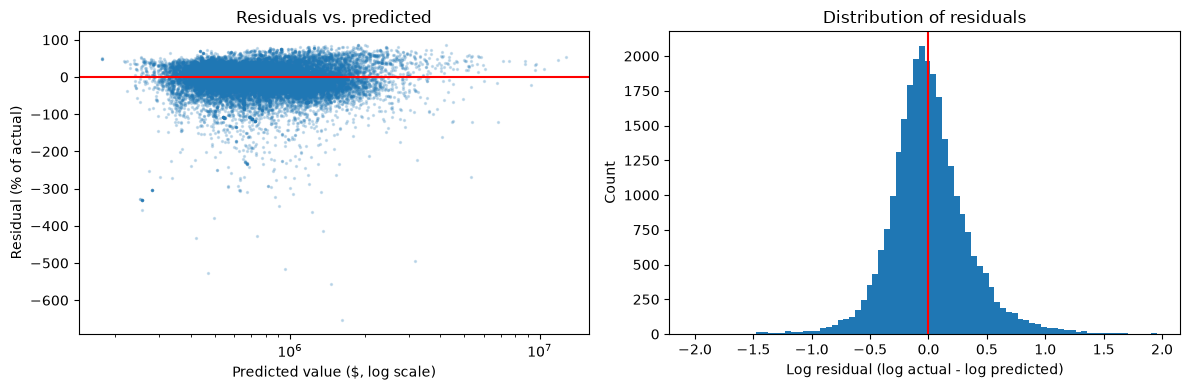

In [5]:
plot_residuals(y_test, lin_pred)